# Predicting Bodily Injury Claim Severity

**Goal.** Predict `BodilyInjury`, the dollar cost of a bodily-injury claim, from policyholder and vehicle characteristics, using a GLM and comparing it against a decision tree.

**Data.** `auto_claims.csv`: 250,000 policy records (2017-2021) with driver attributes (`Age`, `Sex`, `MaritalStatus`, `Credit`, `Drivers`), vehicle attributes (`Miles`, `YearsOwned`, `CarAge`, `Value`), and claim outcomes (`Claims`, `BodilyInjury`).

**Findings.** `Age` is a strong predictor of `BodilyInjury`, we see a sharp decrease in `BodilyInjury` from Age 17 to 27, then it levels out and increases slightly from there on as `Age` increases. `YearsOwned` and `Credit` are found to not be statistically significant improvements via `Likelihood Ratio Tests` and their coefficients in the models can't be proven to be non-zero from `p-values`.

**Tools** This project mainly uses statsmodels general linear models, but also matplotlib, numpy, and pandas. Also, sklearn is used for decision trees.

**Aggregation Analysis** Data points can be grouped by nearby `Age` values to try to average out the noise in the `BodilyInjury` variable. `Age` values are kept similar to the original dataset, but `BodilyInjury` is smoothed by this process. This results in being able to fit a Gaussian Log Linked model with much less `RMSE` and better scores for goodness of fit metrics like `LRT` and `Pseudo R2`.  

**Roadmap**

| Task | What happens |
|---|---|
| 1 | Exploratory data analysis, cleaning, log transforms |
| 2 | Relationships between predictors and the target, Feature Engineering |
| 3 | Consider choice of model family for this project's goals (GLM vs. tree) |
| 4 | Fit and evaluate three GLMs (Gaussian identity, Gaussian log, Inverse Gaussian log) |
| 5 | Fit a decision tree for comparison |
| 6 | Controlling for Noise and improving model fit with Data Aggregation|



## Setup: libraries

In [ ]:
# @title

# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats


# ---------------------------------------------------------------------------
# Plot helpers: keep every chart compact (few ticks, short labels, small markers)
# ---------------------------------------------------------------------------
from matplotlib.ticker import MaxNLocator, FuncFormatter

def short_num(x, pos=None):
    """Format 200000 -> 200k, 1500000 -> 1.5M. Numbers under 10,000 (e.g. years) are left alone."""
    if abs(x) >= 1e6:
        return f"{x/1e6:g}M"
    if abs(x) >= 1e4:
        return f"{x/1e3:g}k"
    return f"{x:g}"

def shorten_axis(ax, axis="both", nbins=5):
    """Cap the number of ticks on an axis and use short labels (200k, 1.5M)."""
    targets = {"x": [ax.xaxis], "y": [ax.yaxis], "both": [ax.xaxis, ax.yaxis]}[axis]
    for a in targets:
        a.set_major_locator(MaxNLocator(nbins=nbins))
        a.set_major_formatter(FuncFormatter(short_num))

def plot_pred_vs_actual(df, target_var="BodilyInjury", pred_var="predict",
                        title="Predicted vs. actual", s=4, alpha=0.3):
    """Predicted vs. actual scatter with the y = x reference line."""
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.scatter(df[target_var], df[pred_var], s=s, alpha=alpha)

    # Span the full range of both axes so the line covers all the points
    lims = [min(df[pred_var].min(), df[target_var].min()),
            max(df[pred_var].max(), df[target_var].max())]
    ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="y = x")

    ax.set_xlabel(f"Actual {target_var}")
    ax.set_ylabel("Predicted")
    ax.set_title(title, fontsize=10)
    shorten_axis(ax)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

def plot_sorted_actual_vs_pred(df, target_var="BodilyInjury", pred_var="predict",
                               title=None, ms=2, alpha=0.1):
    """Actual and predicted values side by side: rows sorted by actual, then by predicted."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    if title:
        fig.suptitle(title, fontsize=11)
    for ax, sort_col in zip(axes, [target_var, pred_var]):
        s = df[[target_var, pred_var]].sort_values(by=sort_col).reset_index(drop=True)
        for col in (target_var, pred_var):
            ax.plot(s.index, s[col], ".", ms=ms, alpha=alpha, label=col)
        ax.set_title(f"Sorted by {sort_col}", fontsize=10)
        ax.set_xlabel("Row rank")
        shorten_axis(ax)
    axes[0].set_ylabel("Value")
    leg = axes[0].legend(markerscale=4, fontsize=8, loc="upper left")
    for h in leg.get_lines():
        h.set_alpha(1)
    fig.tight_layout(rect=[0, 0, 1, 0.93] if title else None)
    plt.show()

def plot_residual_diagnostics(fitted, resid, title=None):
    """One compact row: residuals vs. fitted, normal Q-Q plot, histogram of residuals."""
    fitted, resid = np.asarray(fitted), np.asarray(resid)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 3.6))
    if title:
        fig.suptitle(title, fontsize=12)

    ax1.scatter(fitted, resid, s=2, alpha=0.2)
    ax1.axhline(0, color="red", linestyle="--", linewidth=1)
    ax1.set_title("Residuals vs. fitted", fontsize=10)
    ax1.set_xlabel("Fitted values")
    ax1.set_ylabel("Residuals")
    shorten_axis(ax1)

    stats.probplot(resid, dist="norm", plot=ax2)
    ax2.get_lines()[0].set_markersize(2)
    ax2.set_title("Normal Q-Q plot", fontsize=10)
    shorten_axis(ax2, "y")

    ax3.hist(resid, bins=30, density=True)
    xs = np.linspace(resid.min(), resid.max(), 200)
    ax3.plot(xs, stats.gaussian_kde(resid)(xs), color="orange")   # density curve
    ax3.set_title("Histogram of residuals", fontsize=10)
    ax3.set_xlabel("Residual")
    shorten_axis(ax3, "x", nbins=4)

    fig.tight_layout(rect=[0, 0, 1, 0.92] if title else None)
    plt.show()




---



## Source Data Variable Definitions

| Variable | Definition | Type |
|---|---|---|
| `BodilyInjury` | Total bodily injury costs – **target variable** to be predicted | Numeric |
| `Year` | Year of the policy | Numeric |
| `Age` | Age of the primary driver | Numeric |
| `Credit` | Credit score, A – H, where A is the best score | Factor |
| `Sex` | M or F | Factor |
| `MaritalStatus` | Married, Divorced, Widowed, or Single | Factor |
| `Miles` | Vehicle mileage | Numeric |
| `Drivers` | Number of drivers | Numeric |
| `CarAge` | Age of the vehicle | Numeric |
| `Value` | Value of the vehicle | Numeric |
| `YearsOwned` | Number of years the main driver has owned the vehicle | Numeric |
| `Claims` | Number of people incurring bodily injury in the accident | Numeric |


## Load the data

In [ ]:
# @title

auto_claims = pd.read_csv("auto_claims.csv")
auto_claims.head()

,Year,Age,Credit,Sex,MaritalStatus,Miles,YearsOwned,CarAge,Value,BodilyInjury,Drivers,Claims
0,2017,25,F,F,Single,3000,5,10,4843,4912,4,2
1,2017,21,A,F,Married,10000,1,10,6228,6185,2,2
2,2017,30,E,M,Single,21000,5,8,10000,759,1,1
3,2017,67,A,F,Single,5000,2,19,588,7728,1,2
4,2017,53,B,M,Single,6000,1,2,13000,4050,1,2




---



# 1. Exploratory Data Analysis, Cleaning, and Variable Transforms:


*   Checking for missing values, zeros, and outliers and make adjustments to the data, removing rows and adding transformed variables as justified.

*   Creating Histograms for the variables of potential interest. These include
`BodilyInjury` as the target variable as well as `Claims` as another outcome variable, and predictors such as `Age`, `Sex`, `MaritalStatus`, `Credit`, `Drivers`, `Miles`, `YearsOwned`, `CarAge`, and `Value`. For right-skewed variables log-transformations are applied where appropriate.




### Summary of the Data

Every numeric column has all `250,000` values present. `BodilyInjury` (max 565,229 vs. 75th percentile 14,386) and `Value` (max 207,611) look heavily right-skewed.

In [ ]:
# @title

auto_claims.describe()
# maybe YearsOwned, CarAge shouldnt have 0s? (No upon looking at the hist 0s dont seem weird)
# I dont see any missing values
# maybe Value and BodilyInjury have outliers?

,Year,Age,Miles,YearsOwned,CarAge,Value,BodilyInjury,Drivers,Claims
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,2019.000000,48.295892,10233.580000,2.185408,6.192616,17379.714228,11295.107604,1.649440,1.688328
std,1.414216,14.568347,4047.281298,2.503088,4.199276,16570.682882,14106.413306,0.810648,0.497310
min,2017.000000,17.000000,1000.000000,0.000000,0.000000,361.000000,0.000000,1.000000,0.000000
25%,2018.000000,37.000000,8000.000000,0.000000,3.000000,7500.000000,2900.000000,1.000000,1.000000
50%,2019.000000,49.000000,10000.000000,1.000000,6.000000,13000.000000,6850.000000,1.000000,2.000000
75%,2020.000000,59.000000,13000.000000,3.000000,9.000000,20000.000000,14386.000000,2.000000,2.000000
max,2021.000000,80.000000,21000.000000,12.000000,22.000000,207611.000000,565229.000000,4.000000,2.000000


### Histograms of Each Variable

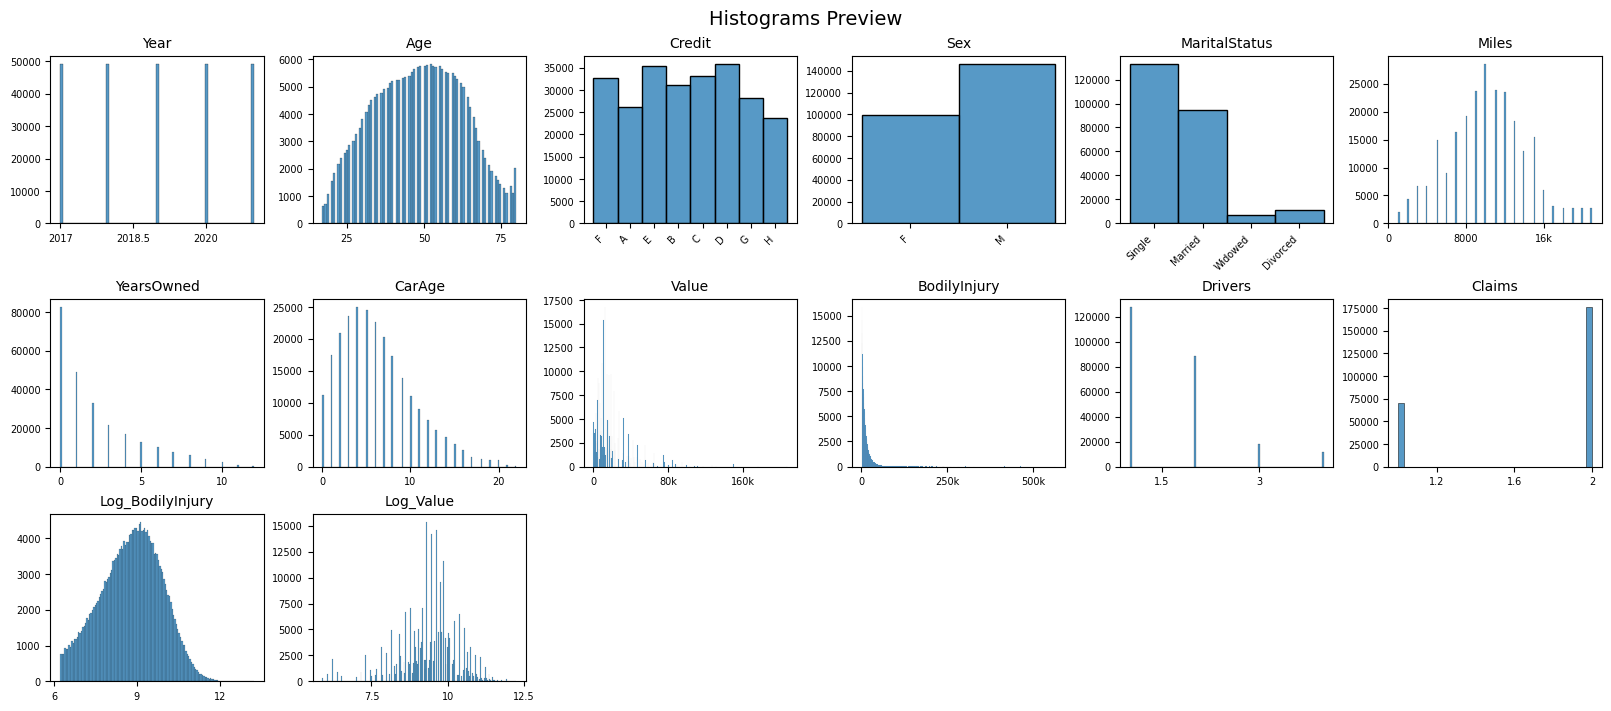

In [ ]:
# @title
labels = auto_claims.columns.tolist()
n_cols = 6                                   # more columns = fewer rows = shorter figure
n_rows = -(-len(labels) // n_cols)

fig_h = 7                                    # total height is fixed; adjust this one number
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, fig_h),
                         constrained_layout=True)
fig.suptitle("Histograms Preview", fontsize=14)

for ax, l in zip(axes.flat, labels):
    sns.histplot(auto_claims[l], ax=ax)
    ax.set_title(l, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")                        # frees up horizontal space
    ax.tick_params(axis="both", labelsize=7)

    if pd.api.types.is_numeric_dtype(auto_claims[l]):
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(FuncFormatter(short_num))
    else:
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

for ax in axes.flat[len(labels):]:
    ax.set_visible(False)

plt.show()


### Observations from the Histograms:

- `Age` has a spike at exactly 80, so 80 most likely means "80 or older" (a capped value). However, this is speculation so we will leave it in for now.
- `BodilyInjury` and `Value` are right skewed.
- `Claims` of 0 are a small portion of our data



### Next Step: Filter and Transform the Data

- Keep rows with **`Claims > 0`**: the model predicts the cost *given* that an accident claim occurred, and `BodilyInjury` is 0 when there are no claims.

The result is stored as `auto_claims` (245,902 rows after filtering).

`BodilyInjury` and `Value` have very long right tails. Therefore they are candidates for log transforms. We add `Log_BodilyInjury` and `Log_Value` to the data as variables.

In [ ]:
# @title
# remove instances where there are no claims since we are trying to predict the BI of claims when there is an accident,
# we know BI is 0 when there are no claims
auto_claims = auto_claims[(auto_claims["Claims"]>0)]

auto_claims["Log_BodilyInjury"] = np.log(auto_claims["BodilyInjury"])
auto_claims["Log_Value"] = np.log(auto_claims["Value"])

### Histograms after Filtering and Log Transforms

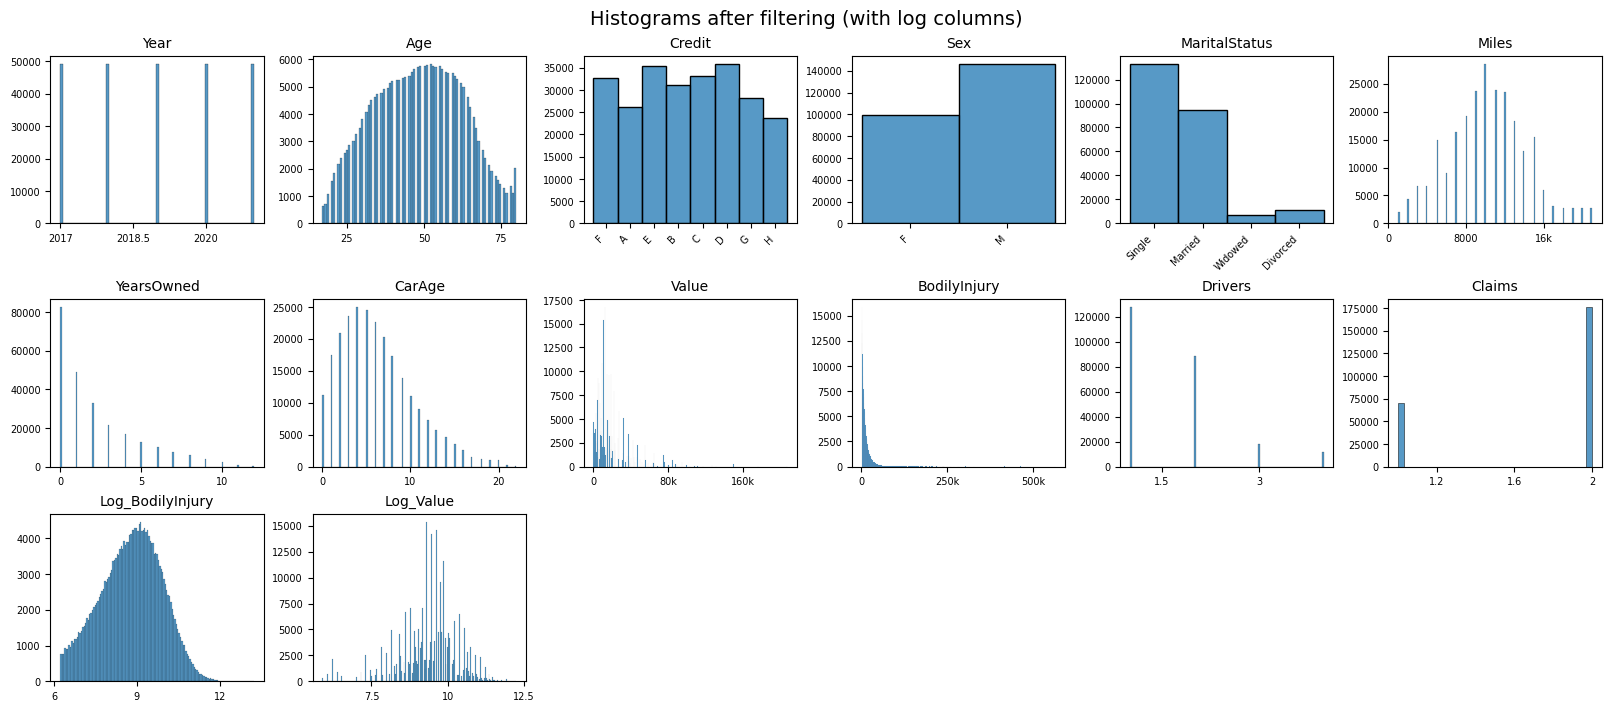

In [ ]:
# @title
labels = auto_claims.columns.tolist()
n_cols = 6                                   # more columns = fewer rows = shorter figure
n_rows = -(-len(labels) // n_cols)

fig_h = 7                                    # total height is fixed; adjust this one number
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, fig_h),
                         constrained_layout=True)
fig.suptitle("Histograms after filtering (with log columns)", fontsize=14)

for ax, l in zip(axes.flat, labels):
    sns.histplot(auto_claims[l], ax=ax)
    ax.set_title(l, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")                        # frees up horizontal space
    ax.tick_params(axis="both", labelsize=7)

    if pd.api.types.is_numeric_dtype(auto_claims[l]):
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(FuncFormatter(short_num))
    else:
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

for ax in axes.flat[len(labels):]:
    ax.set_visible(False)

plt.show()

# 2. Exploring Relationships of Predictor Variables to the Target.

Creating charts that look at the Target variable grouped by each value for the predictors. This allows us to see the general relationship (how the mean moves across values) as well as the amount of variation within each value group.

Boxplots and Scatterplots of grouped means are used.


### Task 2 setup: lists of predictors and targets

In [ ]:
# @title

predictors = auto_claims.columns.tolist()
predictors.remove("BodilyInjury")
predictors.remove("Log_BodilyInjury")

targets = ["BodilyInjury","Log_BodilyInjury","Claims"]

### Boxplots: `Log Bodily Injury` by each Categorical Predictor

Each panel shows the spread of `Log_BodilyInjury` at every level of a categorical or low-cardinality variable.

`Sex`, `Credit`, `MaritalStatus`, `Year`, `Drivers`,
                     `Miles`, `YearsOwned`, `CarAge`

`Claims` is included out of interest, but will not be used as a predictor, because it is not known before the loss.

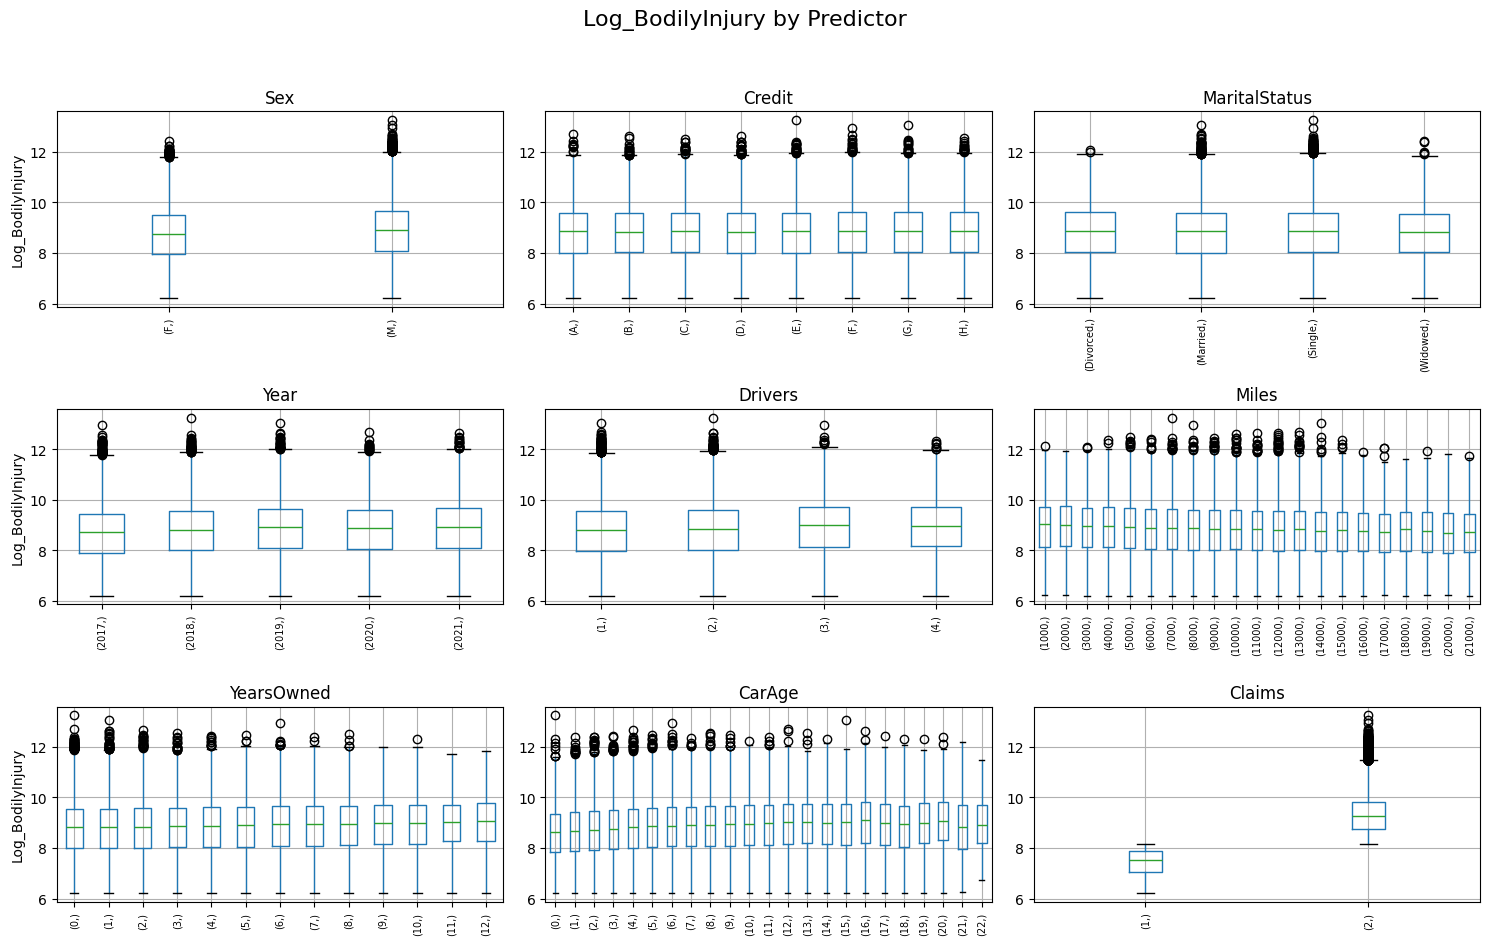

In [ ]:
# @title
categorical_vars = ["Sex", "Credit", "MaritalStatus", "Year", "Drivers",
                    "Miles", "YearsOwned", "CarAge","Claims"]

n_cols = 3
n_rows = -(-len(categorical_vars) // n_cols)   # 3 rows

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.2 * n_rows))

for ax, l in zip(axes.flat, categorical_vars):
    auto_claims.boxplot(["Log_BodilyInjury"], by=[l], ax=ax)
    ax.set_title(l)                     # replaces pandas' default "Log_BodilyInjury"
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)   # many levels in Miles / CarAge

for ax in axes[:, 0]:                   # y label only on the left column
    ax.set_ylabel("Log_BodilyInjury")

fig.suptitle("Log_BodilyInjury by Predictor", fontsize=16)   # overrides pandas' "Boxplot grouped by ..."
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Scatterplots: Continuous Predictors vs. `Log_BodilyInjury`

`Value` and `Log_Value` show no visible trend against the target, which supports removing them. `Age` shows elevated claim costs for the youngest drivers and a fairly flat pattern after that.

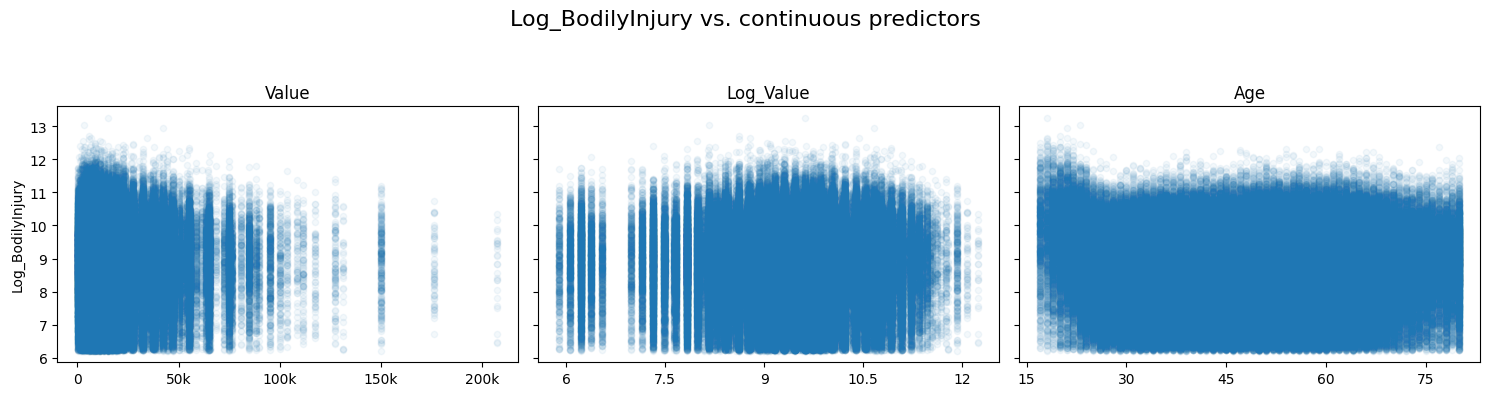

In [ ]:
# @title
# Continuous variables vs. the log target
numeric_vars = ["Value", "Log_Value", "Age"]

fig, axes = plt.subplots(1, len(numeric_vars), figsize=(15, 4), sharey=True)
fig.suptitle("Log_BodilyInjury vs. continuous predictors", fontsize=16)

for ax, l in zip(axes, numeric_vars):
    auto_claims.plot.scatter(x=l, y="Log_BodilyInjury", ax=ax, alpha=0.05)
    ax.set_title(l)
    ax.set_xlabel("")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FuncFormatter(short_num))

axes[0].set_ylabel("Log_BodilyInjury")
for ax in axes[1:]:
    ax.set_ylabel("")

fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Mean `Log_BodilyInjury` grouped by `Age`, `Log_Value` and `Value`

Averaging the target within each level of a variable shows its basic shape.

- **`Age`:** average cost falls steeply from age 17 until the high 20s, then stays roughly flat with a slight upward drift. This kink motivates splitting `Age` into two pieces (a knot near age 27) in the feature engineering step.
- **`Log_Value and Value`:** the means scatter between roughly 8.5 and 9.2 with no consistent trend, and get noisier at high values where there are few rows. Together with the scatterplots above, this supports dropping `Value` and `Log_Value`.

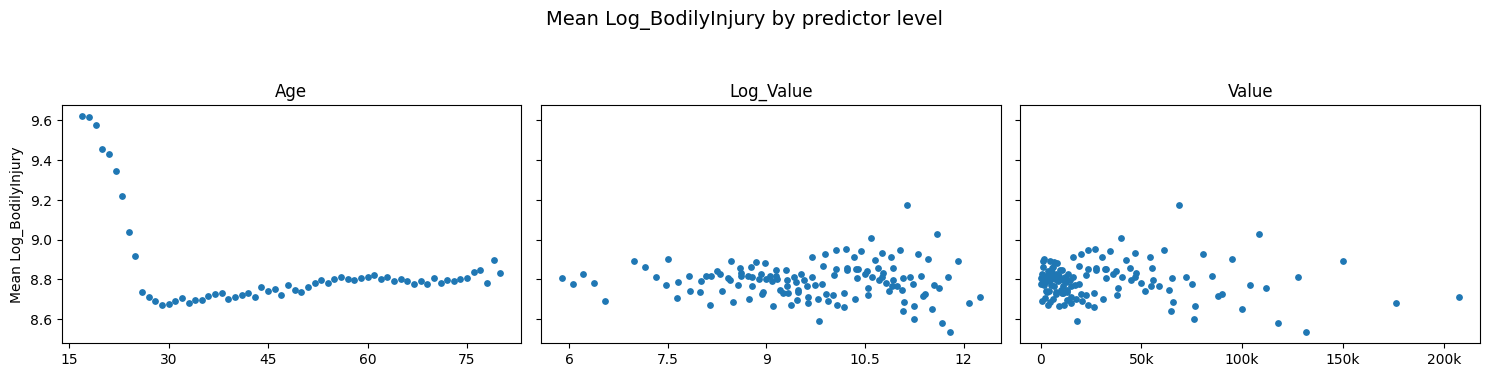

In [ ]:
# @title
# Mean of Log_BodilyInjury at each level of Age, Log_Value and Value
vars_to_check = ["Age", "Log_Value", "Value"]

fig, axes = plt.subplots(1, len(vars_to_check), figsize=(15, 3.8), sharey=True)
fig.suptitle("Mean Log_BodilyInjury by predictor level", fontsize=14)

means = {}
for ax, v in zip(axes, vars_to_check):
    means[v] = auto_claims.groupby(v)["Log_BodilyInjury"].mean().reset_index()
    ax.scatter(means[v][v], means[v]["Log_BodilyInjury"], s=15)
    ax.set_title(v)
    ax.set_xlabel("")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FuncFormatter(short_num))

axes[0].set_ylabel("Mean Log_BodilyInjury")
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Mean log claim cost by every predictor

The group mean of `Log_BodilyInjury` for each predictor (`Miles` is shown in thousands). For example, `CarAge` rises up to roughly 13 years, then flattens and becomes noisy where the counts are small.

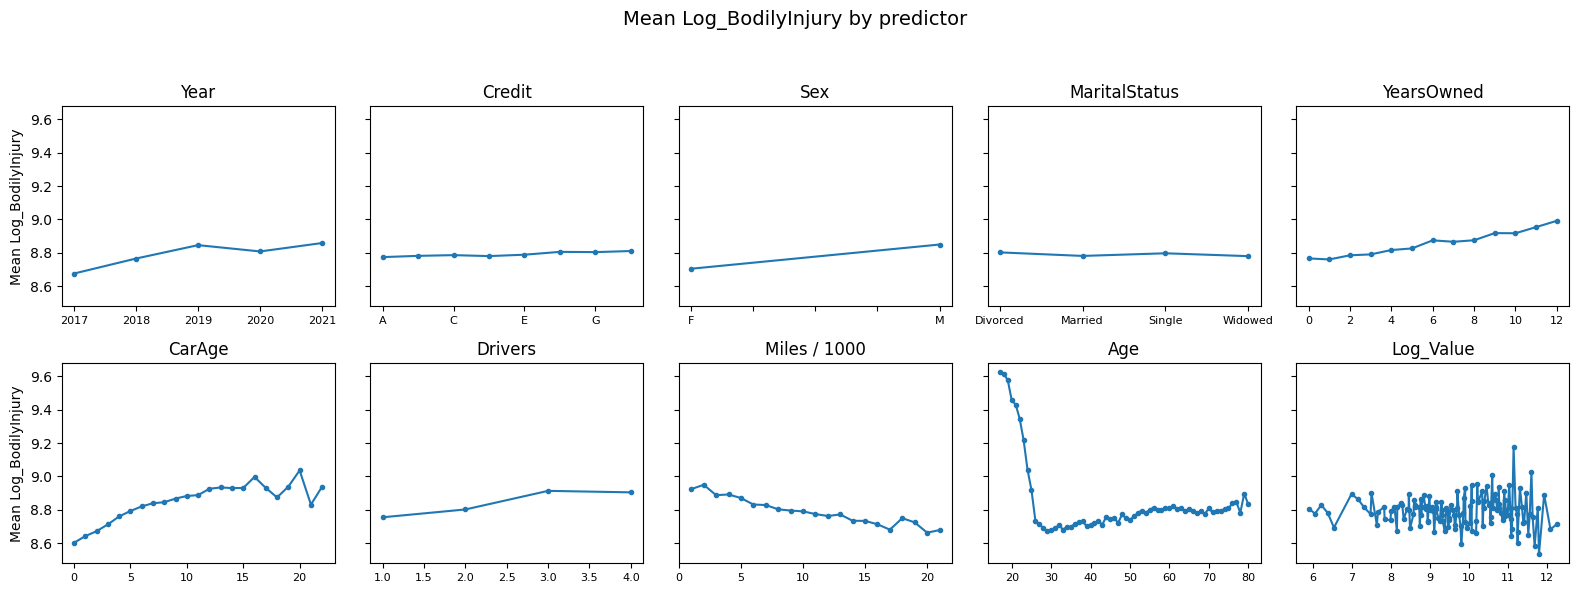

In [ ]:
# @title
target = "Log_BodilyInjury"
cols = ["Year", "Credit", "Sex", "MaritalStatus",
        "YearsOwned", "CarAge", "Drivers", "Miles", "Age", "Log_Value"]

summaries = {}   # keep the tables in case you want to inspect them

n_cols = 5
n_rows = -(-len(cols) // n_cols)   # 2 rows
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows), sharey=True)
fig.suptitle(f"Mean {target} by predictor", fontsize=14)

for ax, col in zip(axes.flat, cols):
    key = auto_claims[col] / 1000 if col == "Miles" else auto_claims[col]
    label = "Miles / 1000" if col == "Miles" else col

    grp = auto_claims.groupby(key).agg(mean=(target, "mean"),
                                       n=(target, "size"))
    summaries[label] = grp

    grp["mean"].plot(ax=ax, marker="o", markersize=3)
    ax.set_title(label)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)

for ax in axes[:, 0]:
    ax.set_ylabel(f"Mean {target}")

fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()



---



## Next Step: Feature engineering to build the modeling table `BI`

- Drop `Value` and `Log_Value` (no relationship with the target).
- **Piecewise Age:** `AgeLow = min(Age, 27)` and `AgeHigh = max(Age, 27)`. This lets the model fit a steep slope below 27 and a different slope above 27.
- Encode `Credit` (A, B, ... ) as the integer `CreditNum`, and encode `Sex` and `MaritalStatus` numerically.

The resulting table `BI` has 245,902 rows and 14 columns.

In [ ]:
# @title


BI = auto_claims.copy()


# Remove 'Value' and 'lnValue' columns
BI.drop(['Value', 'Log_Value'], axis=1, inplace=True)

# Create 'AgeLow' and 'AgeHigh' variables
BI['AgeLow'] = BI['Age'].apply(lambda x: x if x < 27 else 27)
BI['AgeHigh'] = BI['Age'].apply(lambda x: x if x > 27 else 27)

# Convert 'Credit' to numeric
BI['CreditNum'] = BI['Credit'].astype('category').cat.codes + 1  # Sets A = 1, B = 2, etc.
# Define 'Sex' as numeric
sex_category_mapping = {'F': 0, 'M': 1}
BI['Sex'] = BI['Sex'].map(sex_category_mapping)
# Define 'MaritalStatus' as numeric
marital_category_mapping = {'Single': 0, 'Divorced': 1, 'Married': 2, 'Widowed': 3}
BI['MaritalStatus'] = BI['MaritalStatus'].map(marital_category_mapping)


# Remove 'Credit' column
BI.drop('Credit', axis=1, inplace=True)

print(BI.shape)

# Summary of BI
BI.head()

(245902, 14)


,Year,Age,Sex,MaritalStatus,Miles,YearsOwned,CarAge,BodilyInjury,Drivers,Claims,Log_BodilyInjury,AgeLow,AgeHigh,CreditNum
0,2017,25,0,0,3000,5,10,4912,4,2,8.499436,25,27,6
1,2017,21,0,2,10000,1,10,6185,2,2,8.729882,21,27,1
2,2017,30,1,0,21000,5,8,759,1,1,6.632002,27,30,5
3,2017,67,0,0,5000,2,19,7728,1,2,8.952605,27,67,1
4,2017,53,1,0,6000,1,2,4050,1,2,8.306472,27,53,2


# 3. Model Type Consideration


The target is `numeric` and most relationships look approximately `log-linear`, so a `GLM` is the natural first choice. We consider this againt `tree-based models`

Also it allows for `interpretable coefficients` that describe the relationship between predictor and target.

# 4. Fit the best GLM model

Here we:

– Split the data into training and test sets.

– Fit the models, consider variable coefficient p-values to determine if a feature should be removed, and repeat until no further removals are needed. Likelihood Ratio Tests are also used for this purpose.

– Evaluate the model using the test set and
perform diagnostic checks. Diagnostics include calculations of root-mean-squared errors,
qq-plots, and histograms of residuals.



**Note:** Four different possible models are considered. Interaction and extra terms like polynomial or log transformed terms are not considered here.
1) Normal distribution with an identity link. This is standard regression and can serve as a
useful benchmark.
2) Normal distribution with a log link. This guarantees positive predictions, though the
distribution might not be accurate.
3) Inverse Gaussian with a log link. Accounts for the skewness in the target distribution.
4) Decision Tree with 10 depth. (This is done in section 5)


### Train / test / holdout split

Rows are randomly split 70% **train**, 20% **test**, 10% **holdout** (seed 1000). The models are fit on `BI_train` and judged on `BI_test`. The holdout set (`BI_hold`) is set aside and is not used anywhere else in this notebook.

In [ ]:
# @title

# First, prepare the data.

# Before evaluating each model, the dataset will be split into training, testing, and holdout sets.
from sklearn.model_selection import train_test_split
import numpy as np

# Set seed for reproducibility
np.random.seed(1000)

# Partition the data into training (70%) and testing (30%) sets
train_indices = train_test_split(
    BI.index,
    train_size=0.7,
    random_state=1000
)[0]
BI_train = BI.loc[train_indices]
BI_test = BI.drop(train_indices)

# Further partition the testing set into test (2/3) and hold (1/3)
test_indices = train_test_split(
    BI_test.index,
    train_size=2/3,
    random_state=1000
)[0]
BI_hold = BI_test.drop(test_indices)
BI_test = BI_test.loc[test_indices]

# Remove temporary variables
del train_indices
del test_indices

## Initial Gaussian (Identity Link) Fit and Variable Selection

---



### Full model: All Candidate Predictors

With no `family` argument, `smf.glm` defaults to Gaussian with identity link, which is ordinary linear regression. This starts with all ten predictors.

In [ ]:
# @title
glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeHigh + AgeLow + CreditNum' ,
    data=BI_train,
    # family=sm.families.Gaussian()
).fit()

print(glm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           BodilyInjury   No. Observations:               172131
Model:                            GLM   Df Residuals:                   172120
Model Family:                Gaussian   Df Model:                           10
Link Function:               Identity   Scale:                      1.8993e+08
Method:                          IRLS   Log-Likelihood:            -1.8848e+06
Date:                Sat, 21 Nov 2026   Deviance:                   3.2691e+13
Time:                        18:50:37   Pearson chi2:                 3.27e+13
No. Iterations:                     3   Pseudo R-squ. (CS):            0.05139
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -1.089e+06    4.8e+04    -22.657

### Reduced model after removing non-significant variables

`YearsOwned` and `CreditNum` were not significant, so they are dropped.

In [ ]:
# @title

glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeHigh + AgeLow' ,
    data=BI_train,
).fit()


print(glm2.summary())      # full table: coefficients, std errors, z-values, p-values


                 Generalized Linear Model Regression Results                  
Dep. Variable:           BodilyInjury   No. Observations:               172131
Model:                            GLM   Df Residuals:                   172122
Model Family:                Gaussian   Df Model:                            8
Link Function:               Identity   Scale:                      1.8993e+08
Method:                          IRLS   Log-Likelihood:            -1.8848e+06
Date:                Sat, 21 Nov 2026   Deviance:                   3.2692e+13
Time:                        17:39:44   Pearson chi2:                 3.27e+13
No. Iterations:                     3   Pseudo R-squ. (CS):            0.05137
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      -1.09e+06   4.77e+04    -22.836

**Reading the fit.** Pseudo R-squared is only about 0.05, so most of the variation in claim size is unexplained noise.

`AgeLow` (negative) + `Sex` (positive) are impactful predictors.

In [ ]:
# @title
# Now all our variables are significant but we have a fairly low Pseudo R-Squared of 0.05233, so our predictions are dominated by noise.

#the AgeLow has a big impact on BI, as well as Sex and Drivers, and maybe CarAge and Year

### Predicted vs. actual on the test set

Points on the red dashed line would be perfect predictions. Here the predictions stay in a narrow band (roughly 5,000 to 35,000) while actual claims run past 250,000, so large claims fall far below the line.

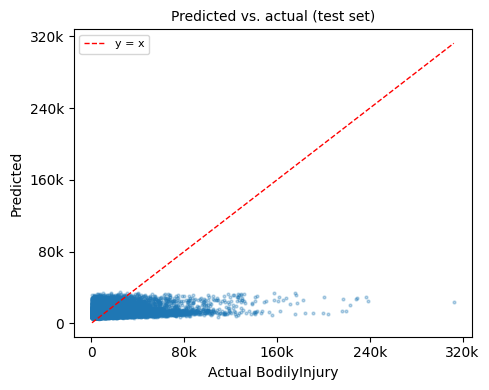

In [ ]:
# @title

BI_test["predict"] = glm2.predict(BI_test)
target_var = "BodilyInjury"

plot_pred_vs_actual(BI_test, target_var, title="Predicted vs. actual (test set)")

### Actual vs. predicted, sorted two ways

Left: rows sorted by actual claim size. Right: rows sorted by predicted size. This shows that the predictions cover a narrow range compared to the actuals.

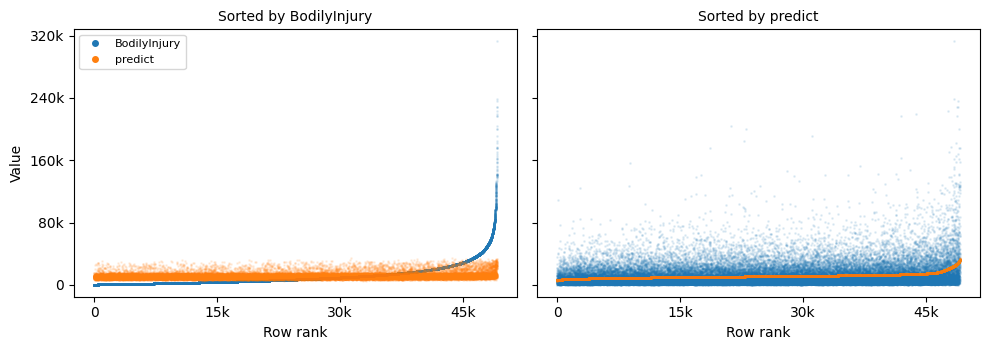

In [ ]:
# @title

plot_sorted_actual_vs_pred(BI_test, "BodilyInjury", "predict", ms=2, alpha=0.1)

 **Takeaway.** The model is dominated by noise or by information not in the data.

## Alternative models

Now that we looked at a standard `Gaussian GLM`, we can consider and compare models like `Gaussian with Log Link`, `Inverse Gaussian with Log Link`, and a `Decision Tree Model` as well.

We also include another method of validating predictors: `Likelihood Ratio Tests`

## Likelihood Ratio Tests (LRT)

The model is refit once per predictor with that variable removed and compares log-likelihoods. A small p-value means dropping the variable was statistically significant (can be said to not be 0 impact) in hurting the fit. The LRT Stat shows how much better the model is with that variable included.



### Gaussian (identity link), all Predictors

In [ ]:
# @title


# Alternative Model Predictor Variable Validation

# GAUSSIAN

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

def drop1_lrt(formula_rhs, response, data, family):
    full = smf.glm(f"{response} ~ {formula_rhs}", data=data, family=family).fit()
    terms = [t.strip() for t in formula_rhs.split("+")]
    results = []

    for term in terms:
        reduced_terms = [t for t in terms if t != term]
        reduced = smf.glm(f"{response} ~ {' + '.join(reduced_terms)}",
                          data=data, family=family).fit()

        lrt_stat = 2 * (full.llf - reduced.llf)
        df = full.df_model - reduced.df_model   # handles multi-level categoricals
        results.append({
            'Predictor': term,
            'Df': int(df),
            'LRT Stat': lrt_stat,
            'Pr(>Chi)': chi2.sf(lrt_stat, df)
        })

    return pd.DataFrame(results)

rhs = "Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeHigh + AgeLow + CreditNum"
family = sm.families.Gaussian()

d = drop1_lrt(rhs, "BodilyInjury", BI_train, family)
print(d)

       Predictor  Df     LRT Stat       Pr(>Chi)
0           Year   1   570.798969  3.762874e-126
1            Sex   1   838.003108  2.949428e-184
2  MaritalStatus   1    13.166745   2.849613e-04
3          Miles   1    63.548521   1.564651e-15
4     YearsOwned   1     0.018451   8.919534e-01
5         CarAge   1   617.797836  2.252792e-136
6        Drivers   1   410.293078   3.164689e-91
7        AgeHigh   1   118.617535   1.270012e-27
8         AgeLow   1  5526.915059   0.000000e+00
9      CreditNum   1     3.719355   5.378515e-02


### Gaussian with Log Link, all Predictors

The log link guarantees positive predictions.

In [ ]:
# @title


# Alternative Model Predictor Variable Validation

# GAUSSIAN LOG

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

def drop1_lrt(formula_rhs, response, data, family):
    full = smf.glm(f"{response} ~ {formula_rhs}", data=data, family=family).fit()
    terms = [t.strip() for t in formula_rhs.split("+")]
    results = []

    for term in terms:
        reduced_terms = [t for t in terms if t != term]
        reduced = smf.glm(f"{response} ~ {' + '.join(reduced_terms)}",
                          data=data, family=family).fit()

        lrt_stat = 2 * (full.llf - reduced.llf)
        df = full.df_model - reduced.df_model   # handles multi-level categoricals
        results.append({
            'Predictor': term,
            'Df': int(df),
            'LRT Stat': lrt_stat,
            'Pr(>Chi)': chi2.sf(lrt_stat, df)
        })

    return pd.DataFrame(results)

rhs = "Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeHigh + AgeLow + CreditNum"
family = sm.families.Gaussian(sm.families.links.Log())

d = drop1_lrt(rhs, "BodilyInjury", BI_train, family)
print(d)

       Predictor  Df     LRT Stat       Pr(>Chi)
0           Year   1   651.645106  9.802429e-144
1            Sex   1  1304.011450  1.518722e-285
2  MaritalStatus   1     8.704586   3.174106e-03
3          Miles   1    85.400654   2.436400e-20
4     YearsOwned   1     0.134003   7.143168e-01
5         CarAge   1   627.037452  2.203691e-138
6        Drivers   1   471.350164  1.629161e-104
7        AgeHigh   1    66.817346   2.978656e-16
8         AgeLow   1  6080.050548   0.000000e+00
9      CreditNum   1     7.567353   5.943500e-03


### Re-test after removing `YearsOwned` and `CreditNum`

In the full-model tests above, `YearsOwned` is clearly not significant with high p values. `CreditNum` is not significant either, but more on the edge. Both are dropped here. After removing them, every remaining term is significant. `MaritalStatus` has the smallest LRT statistic of those left, so it is the next candidate if further simplification is wanted.

In [ ]:
# @title


# Here We see that CreditNum and YearsOwned are not Statistically Significantly different from 0 in their LRT Stat.
# also YearsOwned and CreditNum are weak in LRT Stat

# this is the same result we saw before.

# lets try it again for those variables removed

rhs = "Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeHigh + AgeLow"
family = sm.families.Gaussian()

d = drop1_lrt(rhs, "BodilyInjury", BI_train, family)
print("Gaussian")
print(d)

family = sm.families.Gaussian(sm.families.links.Log())

d = drop1_lrt(rhs, "BodilyInjury", BI_train, family)
print("Gaussian Log")
print(d)

# Maybe MaritalStatus Could be removed.

Gaussian
       Predictor  Df     LRT Stat       Pr(>Chi)
0           Year   1   579.946863  3.851581e-128
1            Sex   1   838.817089  1.962338e-184
2  MaritalStatus   1    13.215641   2.776225e-04
3          Miles   1    63.955891   1.272363e-15
4         CarAge   1   787.573157  2.715856e-173
5        Drivers   1   410.649301   2.647223e-91
6        AgeHigh   1   117.267951   2.507904e-27
7         AgeLow   1  5544.136301   0.000000e+00
Gaussian Log
       Predictor  Df     LRT Stat       Pr(>Chi)
0           Year   1   662.650152  3.962715e-146
1            Sex   1  1304.746293  1.051446e-285
2  MaritalStatus   1     8.824587   2.971986e-03
3          Miles   1    85.804909   1.985926e-20
4         CarAge   1   805.187524  4.019801e-177
5        Drivers   1   470.812691  2.132659e-104
6        AgeHigh   1    65.312279   6.392182e-16
7         AgeLow   1  6098.699512   0.000000e+00


## Evaluate these Models


 Look at RMSE and Residual Analysis

 Also consider the Coeffients on each Predictor Variable

### Model A: Gaussian (identity link) with test RMSE and diagnostics

Gaussian: RMSE 13874.831372988692


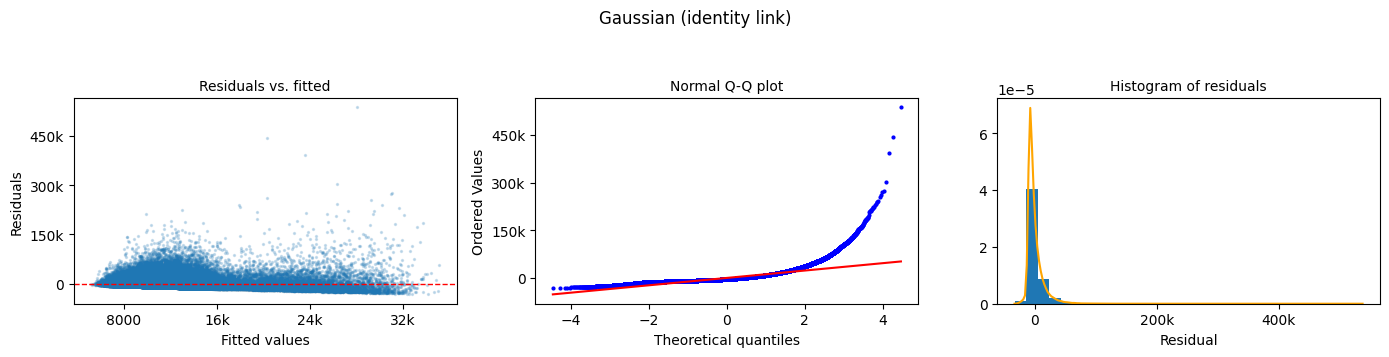

In [ ]:
# @title

# All the remaining variables are statisticall significant.

# Model 3A - Gaussian
# Fit gaussian GLM
glm3a = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeLow + AgeHigh',
    data=BI_train,
    family=sm.families.Gaussian()
).fit()

predict_test = glm3a.predict(BI_test)
rmse = np.sqrt(np.sum((predict_test - BI_test['BodilyInjury'])**2) / len(BI_test))
print("Gaussian: RMSE",rmse)

# Residual diagnostics (compact, one row)
plot_residual_diagnostics(glm3a.fittedvalues, glm3a.resid_response,
                          title="Gaussian (identity link)")


In [ ]:
# @title

glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeHigh + AgeLow' ,
    data=BI_train,
).fit()


print(glm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           BodilyInjury   No. Observations:               172131
Model:                            GLM   Df Residuals:                   172122
Model Family:                Gaussian   Df Model:                            8
Link Function:               Identity   Scale:                      1.8993e+08
Method:                          IRLS   Log-Likelihood:            -1.8848e+06
Date:                Sat, 21 Nov 2026   Deviance:                   3.2692e+13
Time:                        19:05:56   Pearson chi2:                 3.27e+13
No. Iterations:                     3   Pseudo R-squ. (CS):            0.05137
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      -1.09e+06   4.77e+04    -22.836

### Model B: Gaussian (log link) with test RMSE and diagnostics

Gaussian Log: RMSE 13845.86388366694


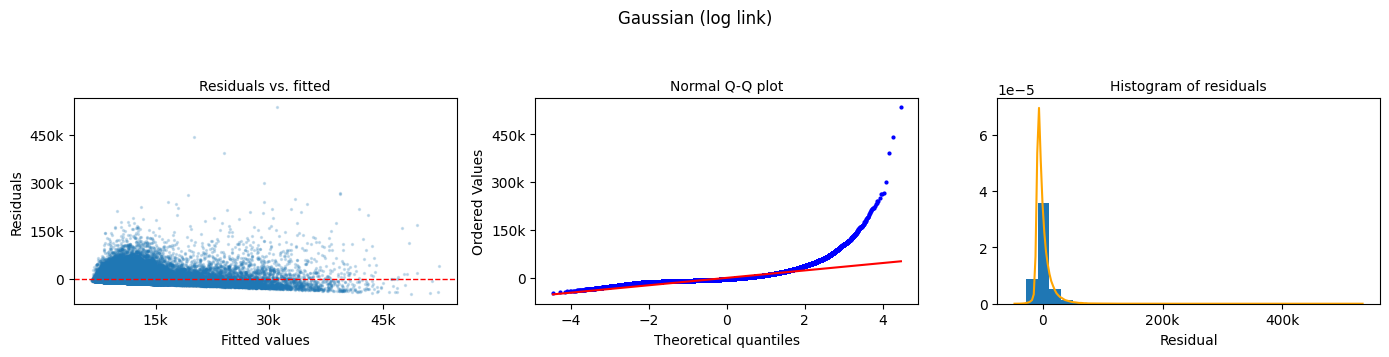

In [ ]:
# @title

# All the remaining variables are statisticall significant.

# Model 3B - Gaussian LOG
# Fit gaussian GLM with Log Link
glm3a = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeLow + AgeHigh',
    data=BI_train,
    family=sm.families.Gaussian(sm.families.links.Log())
).fit()

predict_test = glm3a.predict(BI_test)
rmse = np.sqrt(np.sum((predict_test - BI_test['BodilyInjury'])**2) / len(BI_test))
print("Gaussian Log: RMSE",rmse)

# Residual diagnostics (compact, one row)
plot_residual_diagnostics(glm3a.fittedvalues, glm3a.resid_response,
                          title="Gaussian (log link)")


In [ ]:
# @title

glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeHigh + AgeLow' ,
    data=BI_train,
    family =sm.families.Gaussian(sm.families.links.log())
).fit()


print(glm2.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")


                 Generalized Linear Model Regression Results                  
Dep. Variable:           BodilyInjury   No. Observations:               172131
Model:                            GLM   Df Residuals:                   172122
Model Family:                Gaussian   Df Model:                            8
Link Function:                    log   Scale:                      1.8929e+08
Method:                          IRLS   Log-Likelihood:            -1.8845e+06
Date:                Sat, 21 Nov 2026   Deviance:                   3.2581e+13
Time:                        17:40:42   Pearson chi2:                 3.26e+13
No. Iterations:                    10   Pseudo R-squ. (CS):            0.05474
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       -91.2783      4.058    -22.494

### Inverse Gaussian with log link

This family accommodates right-skewed targets. **Caution on the output below:** several LRT statistics come out *negative*. A reduced model cannot truly fit better than the full model, so negative values mean the comparison is unreliable (for example, a fit that did not converge cleanly). The p-values of 1.0 for those rows should not be read as evidence that the terms are irrelevant.

In [ ]:
# @title

# Now try with Inverse Gaussian with Log Link

rhs = "Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeHigh + AgeLow + CreditNum"
family=sm.families.InverseGaussian(sm.families.links.log())

d = drop1_lrt(rhs, "BodilyInjury", BI_train, family)
print(d)

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")


       Predictor  Df     LRT Stat      Pr(>Chi)
0           Year   1   312.291852  6.917767e-70
1            Sex   1   111.420385  4.786461e-26
2  MaritalStatus   1    37.875760  7.539623e-10
3          Miles   1    -0.665886  1.000000e+00
4     YearsOwned   1     2.637519  1.043664e-01
5         CarAge   1   -47.790694  1.000000e+00
6        Drivers   1    15.867048  6.795160e-05
7        AgeHigh   1  -180.314688  1.000000e+00
8         AgeLow   1 -3529.319614  1.000000e+00
9      CreditNum   1   -12.561666  1.000000e+00


### Retry with a much smaller formula

Given the unreliable output above, I test reduced set, `Year + CarAge`.

In [ ]:
# @title


# We see that YearsOwned is not statistically significant, but Miles, CarAge, Drivers, AgeHigh, AgeLow and CreditNum are all not significant

# Try with YearsOwned variable removed

rhs = "Year + CarAge"
family=sm.families.InverseGaussian(sm.families.links.log())

d = drop1_lrt(rhs, "BodilyInjury", BI_train, family)
print(d)

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")


  Predictor  Df     LRT Stat       Pr(>Chi)
0      Year   1  1045.571252  2.233245e-229
1    CarAge   1   179.169767   7.356923e-41


### Model C: Inverse Gaussian (log link), `Year + CarAge`

Inverse Gaussian Log: RMSE 13861.054037262722


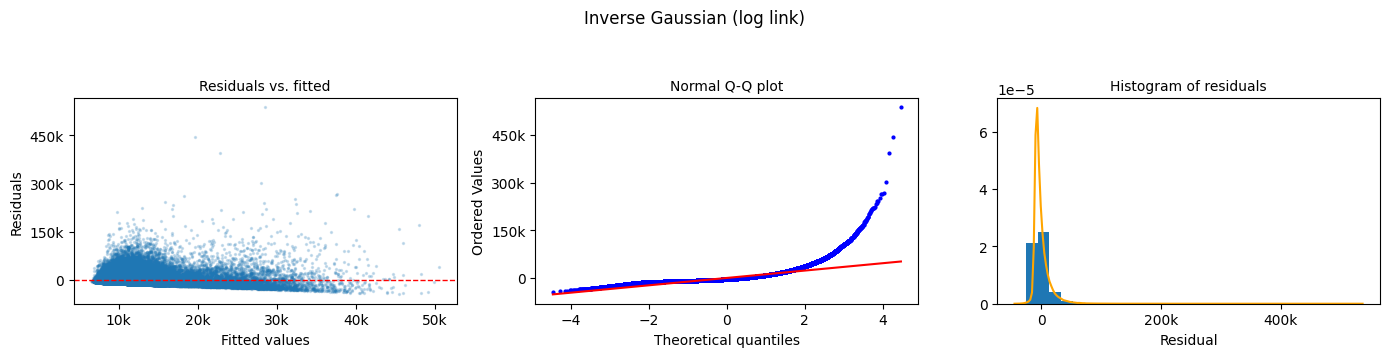

In [ ]:


# Model 3A - Inverse Gaussian Log
# Fit inverse gaussian GLM with log link
glm3a = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeHigh + AgeLow + CreditNum',
    data=BI_train,
    family=sm.families.InverseGaussian(sm.families.links.log())
).fit()

predict_test = glm3a.predict(BI_test)
rmse = np.sqrt(np.sum((predict_test - BI_test['BodilyInjury'])**2) / len(BI_test))
print("Inverse Gaussian Log: RMSE", rmse)

# Residual diagnostics (compact, one row)
plot_residual_diagnostics(glm3a.fittedvalues, glm3a.resid_response,
                          title="Inverse Gaussian (log link)")


In [ ]:
# @title

glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeHigh + AgeLow' ,
    data=BI_train,
    family =sm.families.InverseGaussian(sm.families.links.log())
).fit()


print(glm2.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")


                 Generalized Linear Model Regression Results                  
Dep. Variable:           BodilyInjury   No. Observations:               172131
Model:                            GLM   Df Residuals:                   172122
Model Family:         InverseGaussian   Df Model:                            8
Link Function:                    log   Scale:                      0.00011640
Method:                          IRLS   Log-Likelihood:            -1.7856e+06
Date:                Sat, 21 Nov 2026   Deviance:                       31.873
Time:                        19:16:38   Pearson chi2:                     20.0
No. Iterations:                    17   Pseudo R-squ. (CS):            0.03725
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       -96.6968      3.910    -24.729

### Comparing the three GLMs

The numbers below come from the three fits above (test-set RMSE).

| Model | Test RMSE |
|---|---|
| Gaussian, identity |  13874 |
| Gaussian, log |  13,845 |
| Inverse Gaussian, log | 13,861 |

The Gaussian log model has the lowest RMSE and keeps many significant predictors, so it is the preferred GLM. None of the models predict individual claims well.

These models do show Statistically Significant relationships between the predictors and the target.

`AgeLow` (strong negative relationship)

`AgeHigh` (weak positive relationship)

`Sex` (weak positive relationship of being male)

`Age` seems to be the best predictor.

So people age and get less severe accidents until about 27, while Males have more severe accidents on average.

# 5. Fit the Decision Tree Model
 Fit a tree and obtain the root-
mean-square error.

### Fit a deep decision tree (first pass)

The tree uses every column except the target, its log, `AgeHigh`, `AgeLow`, and `Claims`. It keeps the raw `Age`, since a tree can choose its own split points. It is intentionally deep (`max_depth=10`, `min_samples_leaf=1`) for this first pass.

In [ ]:
# @title
# TASK 5: FIT THE OTHER MODEL
# Fit a tree.

from sklearn.tree import DecisionTreeRegressor
import numpy as np

# Create the decision tree regressor
# Remove specified columns from the feature set
X_train = BI_train.drop(['BodilyInjury', 'Log_BodilyInjury', 'AgeHigh', 'AgeLow',"Claims"], axis=1)
y_train = BI_train['BodilyInjury']

# Initialize and fit the tree
tree_bodily_injury = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)
tree_bodily_injury.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=10, random_state=42)

### Tree RMSE on the test set

Scored on `BI_test`, so it is directly comparable with the GLM test RMSEs above.

### Model D: Decision Tree

RMSE: 14246.87029191394


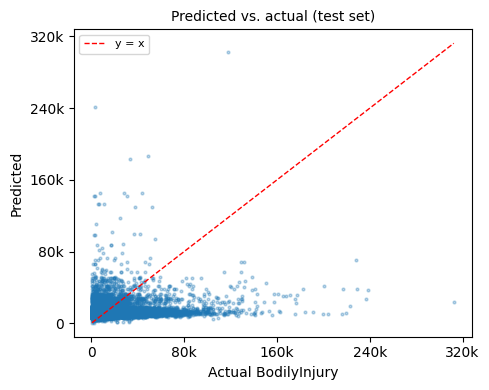

In [ ]:
# @title
X_test = BI_test.drop(['BodilyInjury', 'Log_BodilyInjury', 'AgeHigh', 'AgeLow',"Claims","predict"], axis=1)
y_test = BI_test['BodilyInjury']

# Make predictions and calculate RMSE
predictions_test = tree_bodily_injury.predict(X_test)
rmse = np.sqrt(np.mean((predictions_test - y_test) ** 2))
print(f"RMSE: {rmse}")
BI_test["predict"] = predictions_test
target_var = "BodilyInjury"

plot_pred_vs_actual(BI_test, target_var, title="Predicted vs. actual (test set)")

**Takeaway.** The tree's test RMSE is similar to the three GLMs, but the tree is harder to interpret.

| Model | Test RMSE |
|---|---|
| Gaussian, identity |  13,874 |
| Gaussian, log |  13,845 |
| Inverse Gaussian, log | 13,861 |
| Decision tree (depth 10) | 14,514 |

An unpruned depth-10 tree tends to overfit the training data; pruning or a shallower tree may do better (not tried here).

GridSearch may be applicable for the decision tree, where the holdout may be a useful test. But since the interpretability of the model is important here, the Decision Tree model approach was less explored.

### Interpreting the tree

1. `export_text` prints the first four levels of splitting rules.
2. `plot_tree` draws the top three levels.
3. `feature_importances_` ranks variables by how much they reduced squared error.

The root split is on `Age` (at about 23.5), and `Age` has the largest importance (about 0.34), followed by `CarAge`. This is consistent with the GLM, where the young-driver effect (`AgeLow`) is by far the strongest.

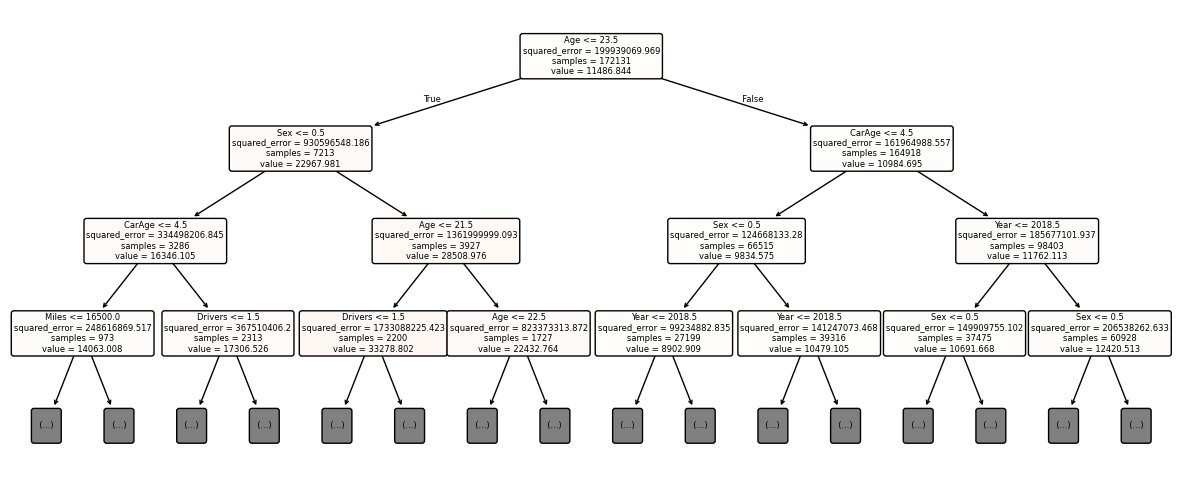

Age              0.337254
Miles            0.149413
CarAge           0.132251
Year             0.083818
Sex              0.081472
CreditNum        0.072354
YearsOwned       0.057570
MaritalStatus    0.050211
Drivers          0.035656
dtype: float64


In [ ]:
# @title

from sklearn.tree import export_text, plot_tree
import matplotlib.pyplot as plt
import pandas as pd

# 1. Text version of the rules
# print(export_text(tree_bodily_injury, feature_names=list(X_train.columns), max_depth=4))

# 2. Plot (only the top levels, otherwise it's unreadable)
plt.figure(figsize=(15, 6))
plot_tree(tree_bodily_injury, feature_names=X_train.columns, max_depth=3,
          filled=True, rounded=True, fontsize=6)
plt.show()

# 3. Which variables matter overall
imp = pd.Series(tree_bodily_injury.feature_importances_, index=X_train.columns)
print(imp.sort_values(ascending=False))



---



# 6. Aggregate Analysis

Maybe there is a chance to reduce noise in the target variable by looking at an aggregate version of the data.

By looking at how the target variable varies around the prediction when sorted by age we can see that `Age` is a possible candidate for averaging or grouping on.

**Aggregation Analysis** Data points can be grouped by nearby `Age` values to try to average out the noise in the `BodilyInjury` variable. `Age` values are kept similar to the original dataset, but `BodilyInjury` is smoothed by this process. This results in being able to fit a Gaussian Log Linked model with much less `RMSE` and better scores for goodness of fit metrics like `LRT` and `Pseudo R2`.  

### How well do predictions track the target across each predictor?

Because the row-level models leave most of the variation unexplained, this step looks at where the predictions and actuals diverge. Each panel sorts the test rows by one feature and plots actual and predicted values. `Age`, `AgeLow` and `AgeHigh` show the clearest structure: young drivers have much higher claims, which the model only partly captures. For the other features the predictions form a flat band beneath a wide cloud of actual values. The `Claims` and `Log_BodilyInjury` panels are not informative (one is a filtered variable, the other a transform of the target).

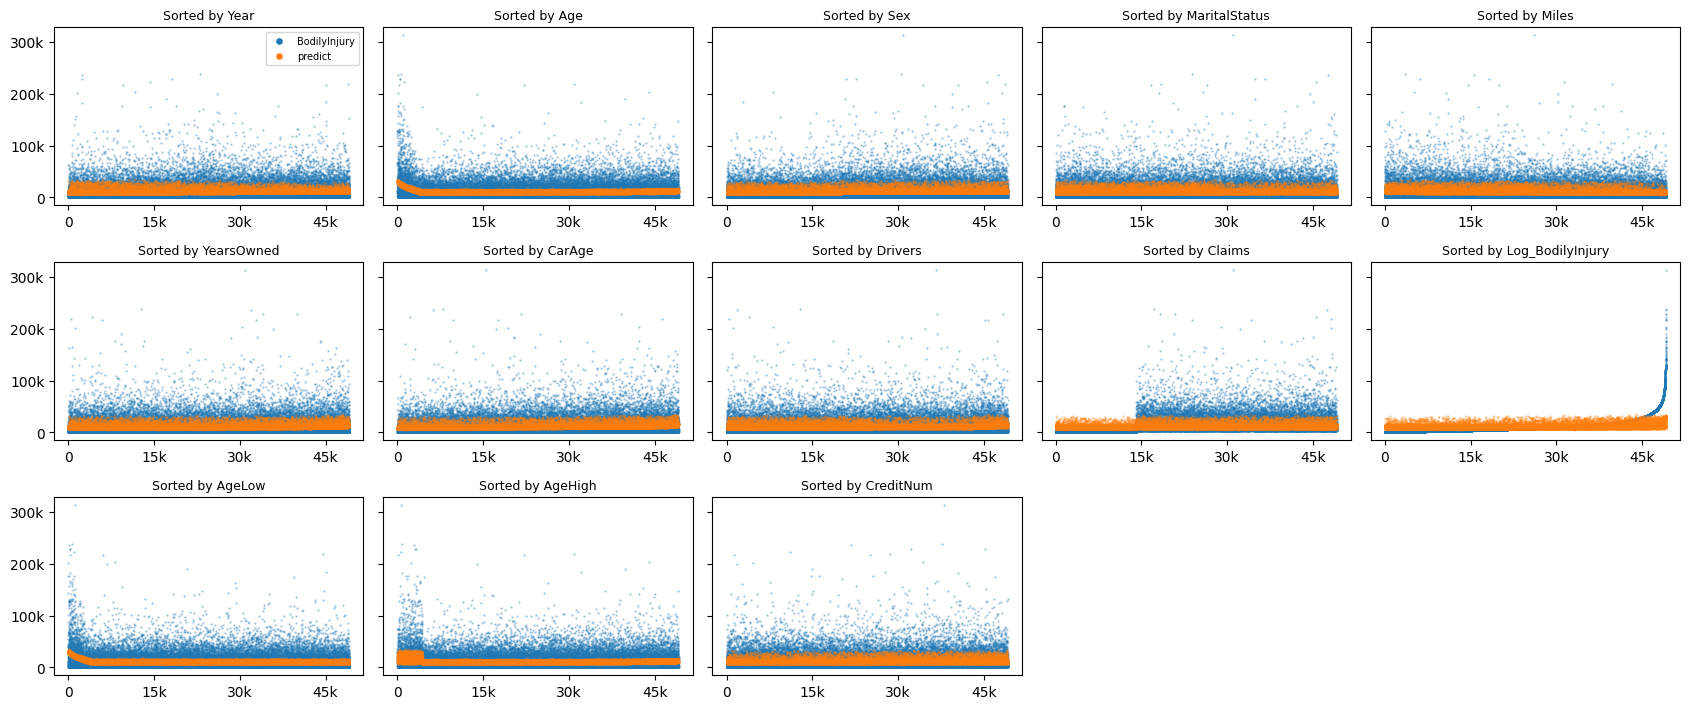

In [ ]:
# @title

# See how each predictor affects the prediction relative to the target in the current model

target_var = "BodilyInjury"
cols = BI_test.columns.tolist()
cols.remove(target_var)
cols.remove("predict")

# One grid of small panels instead of one tall column of plots
n_cols = 5
n_rows = -(-len(cols) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 2.4 * n_rows), sharey=True)

for ax, c in zip(axes.flat, cols):
    s = (BI_test[[target_var, "predict"]]      # Only plot target and predict, NOT c
         .loc[BI_test[c].sort_values().index]  # Sort by feature c
         .reset_index(drop=True))
    ax.plot(s.index, s[target_var], ".", ms=1.5, alpha=0.3, label=target_var)
    ax.plot(s.index, s["predict"], ".", ms=1.5, alpha=0.3, label="predict")
    ax.set_title(f"Sorted by {c}", fontsize=9)
    shorten_axis(ax, nbins=4)

for ax in axes.flat[len(cols):]:               # hide unused panels
    ax.set_visible(False)

leg = axes.flat[0].legend(markerscale=5, fontsize=7, loc="upper right")
for h in leg.get_lines():
    h.set_alpha(1)

fig.tight_layout()
plt.show()

### Build the averaged dataset

Could also just group by age value, but we use groups of a fixed size.

Rows are sorted by `Age` and grouped into blocks of 64 consecutive rows. Each block is replaced by the **mean** of every numeric column. Averaging 64 claims cancels much of the random claim-to-claim noise so the underlying pattern can show. This produces `BI_averaged` (about 3,800 rows).

**Interpretation caveat:** every metric from here on describes predicting a *block average* of 64 claims, not an individual claim, so R-squared and RMSE are not comparable with the earlier models. Also, averaging turns categorical codes such as `Sex` into fractions.

In [ ]:
# @title
def fit_age_bins(train, col="Age", n=50):
    """Learn bin edges from train: n rows per group (equal-count bins)."""
    s = train.sort_values(col).reset_index(drop=True)
    m = (len(s) // n) * n
    s = s.iloc[:m]
    group_id = np.arange(m) // n

    ages = s[col].to_numpy()
    first = ages[::n]                      # first Age of each group
    last = ages[n - 1::n]                  # last Age of each group

    # Interior edges: midpoint between last of group k and first of group k+1
    # (handles gaps between groups, and ties are resolved consistently)
    interior = (last[:-1] + first[1:]) / 2
    edges = np.concatenate([[-np.inf], interior, [np.inf]])  # open-ended so test values outside train range still land in a bin

    # Train group means (the "averaged" table), indexed by bin number
    averaged = s.groupby(group_id).mean(numeric_only=True)
    return edges, averaged


def assign_bin(values, edges):
    """Works for a scalar, array, or Series. Returns bin index 0..k-1."""
    return np.searchsorted(edges, values, side="right") - 1


edges, train_avg = fit_age_bins(BI_train, "Age", n=64)
BI_averaged_train = train_avg

edges, test_avg = fit_age_bins(BI_test, "Age", n=64)
BI_averaged_test = test_avg

### Gaussian log-link GLM on the averaged data, all predictors

In [ ]:
# @title

glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeHigh + AgeLow + CreditNum' ,
    data=BI_averaged_train,
    family=sm.families.Gaussian(sm.families.links.log())
).fit()

print(glm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           BodilyInjury   No. Observations:                 2689
Model:                            GLM   Df Residuals:                     2678
Model Family:                Gaussian   Df Model:                           10
Link Function:                    log   Scale:                      3.0869e+06
Method:                          IRLS   Log-Likelihood:                -23900.
Date:                Sat, 21 Nov 2026   Deviance:                   8.2667e+09
Time:                        19:41:00   Pearson chi2:                 8.27e+09
No. Iterations:                     7   Pseudo R-squ. (CS):             0.8899
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      -170.8294     25.493     -6.701

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")


### Simplified model on averaged data

In the full averaged fit, several terms (for example `MaritalStatus`, p about 0.30) are not significant, leaving `Year + Drivers + AgeHigh + AgeLow`.

In [ ]:
# @title

glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Drivers + AgeHigh + AgeLow' ,
    data=BI_averaged_train,
    family=sm.families.Gaussian(sm.families.links.log())
).fit()

print(glm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           BodilyInjury   No. Observations:                 2689
Model:                            GLM   Df Residuals:                     2684
Model Family:                Gaussian   Df Model:                            4
Link Function:                    log   Scale:                      3.0998e+06
Method:                          IRLS   Log-Likelihood:                -23909.
Date:                Sat, 21 Nov 2026   Deviance:                   8.3198e+09
Time:                        19:41:03   Pearson chi2:                 8.32e+09
No. Iterations:                     7   Pseudo R-squ. (CS):             0.8882
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -169.8869     23.860     -7.120      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")


**Takeaway.** The fit explains most of the variation in the averaged BI (pseudo R-squared about 0.88), so noise is no longer dominating. The model is also simpler.

### Predicted vs. actual on the averaged test set

Points now cluster near the red line.

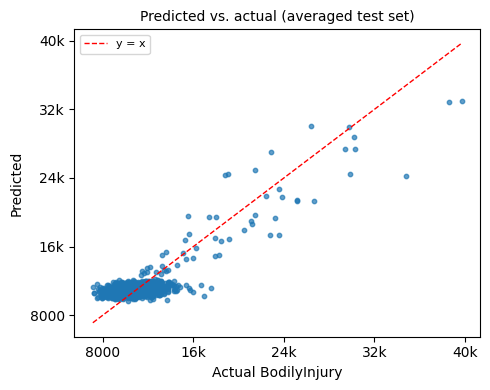

In [ ]:
# @title

BI_averaged_test["predict"] = glm2.predict(BI_averaged_test)
target_var = "BodilyInjury"

plot_pred_vs_actual(BI_averaged_test, target_var, title="Predicted vs. actual (averaged test set)", s=10, alpha=0.7)

### Out-of-sample check: R-squared on test vs. train

This is a measure of how valid the model is on test data.

In [ ]:
# @title

from sklearn.metrics import r2_score

y_pred = glm2.predict(BI_averaged_test)
print("Test R²:", r2_score(BI_averaged_test["BodilyInjury"], y_pred))

# also check train, to see over/underfitting
print("Train R²:", r2_score(BI_averaged_train["BodilyInjury"], glm2.predict(BI_averaged_train)))

Test R²: 0.739976820788335
Train R²: 0.6870389991519593


### Actual vs. predicted, sorted two ways (averaged data)

The predictions follow the actuals much more closely than in the row-level model, including the steep rise at the high end.

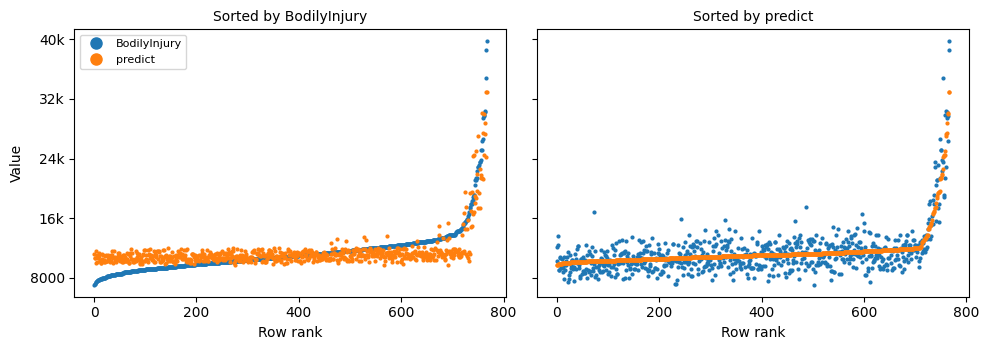

In [ ]:
# @title

plot_sorted_actual_vs_pred(BI_averaged_test, "BodilyInjury", "predict", ms=4, alpha=1.0)

### Diagnostics for the averaged model

Our Residuals are lower magnitude relative to our predictions in this model, as compared to the individual row model, where the residuals were always much larger than the prediction values.

There is still some noise but now our signal mostly dominates.

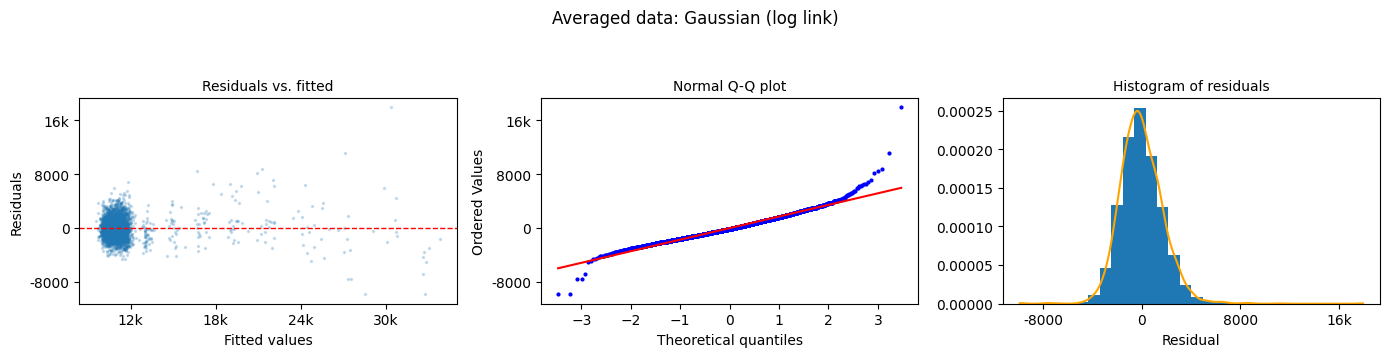

RMSE:  1722.0125159390473


In [ ]:
# @title

# Review the Diagnostics
# Make predictions on test data
predict_test = glm2.predict(BI_averaged_test)
rmse = np.sqrt(np.sum((predict_test - BI_averaged_test['BodilyInjury'])**2) / len(BI_averaged_test))

# print("RMSE: ",rmse)

# Residual diagnostics (compact, one row)
plot_residual_diagnostics(glm2.fittedvalues, glm2.resid_response,
                          title="Averaged data: Gaussian (log link)")

print("RMSE: ",rmse)


## Summary of Modeling Bodily Injury

- **Strongest driver:** driver `Age`, especially under 27. Claim cost drops steeply with age until the late 20s, then is roughly flat. Both the GLM and the tree agree.
- **Other effects** in the Gaussian-log GLM: `Sex`, `Year`, `CarAge`, `Drivers`, and `Miles`, with `MaritalStatus` the weakest of the retained terms. `YearsOwned` and `CreditNum` were dropped after the LRTs.
- **Row-level model comparison:** the Gaussian log-link GLM has the lowest test RMSE, followed by the Gaussian identity GLM, the Inverse Gaussian GLM, and the decision tree. All of them explain little of the variation in individual claims (pseudo R-squared is about 0.05 for the identity-link fit). This type of model is not useful for predicting individual loss, but does show the impact of increasing/decreasing predictor variables.

- **Aggregated target:** averaging 64 similar-aged records gives a much better fit (test R-squared about 0.73), which shows the pattern is real but individual claims are very noisy. Those metrics describe block averages, so they are not comparable with the row-level numbers.